# MorphAlign — image1 / image2 registration demo

This demonstration runs on **two real microscopy images** named generically `image1.tiff` and `image2.tiff`. Their actual staining is not assumed by the algorithm. Image 1 is reference; image 2 is moving. The two images may have different numbers of channels and different spatial dimensions. No ground-truth alignment is available for this example.

Image1: (453, 1152, 3) uint8 | Image2: (1165, 1749) uint16


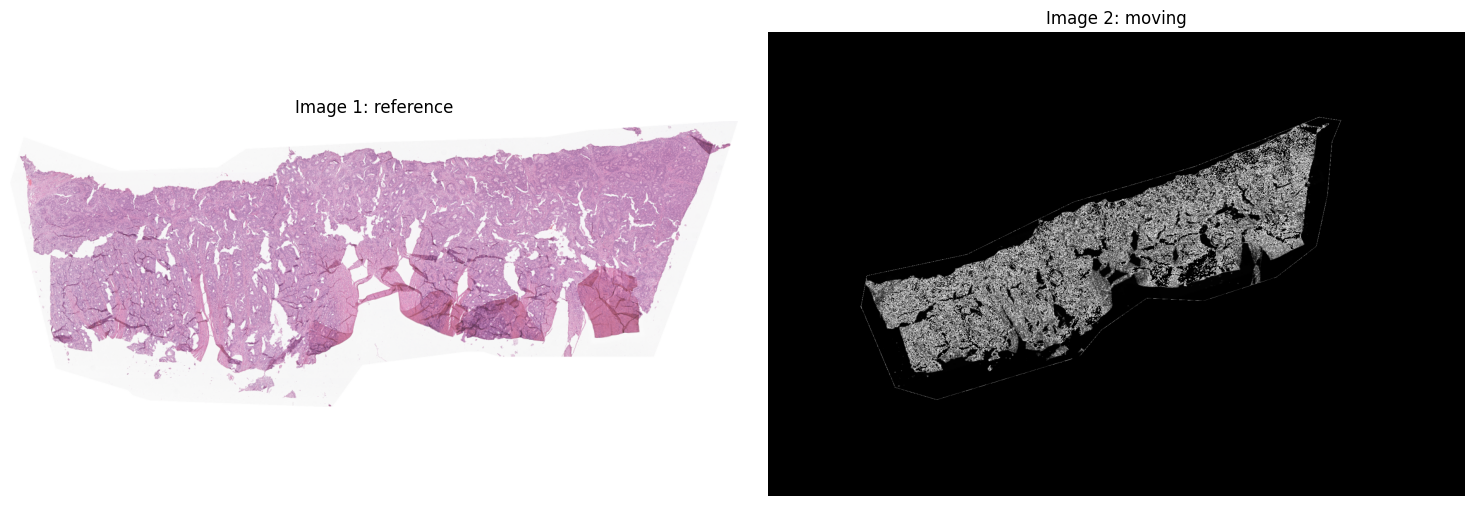

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from morphalign import read_image, preview_rgb, register, export_result
IMAGE1_PATH=Path('examples/image1.tiff')
IMAGE2_PATH=Path('examples/image2.tiff')
image1=read_image(IMAGE1_PATH)
image2=read_image(IMAGE2_PATH)
print('Image1:',image1.shape,image1.dtype,'| Image2:',image2.shape,image2.dtype)
fig,axs=plt.subplots(1,2,figsize=(15,5))
for ax,im,t in zip(axs,[image1,image2],['Image 1: reference','Image 2: moving']):
    ax.imshow(preview_rgb(im));ax.set_title(t);ax.axis('off')
plt.tight_layout();plt.show()

## Run with interactive settings

The feature extractor is generic: it independently normalizes input channels, computes multiscale edge-energy maps, and optimizes a shared spatial transform. Enter `auto` to use all image2 channels, or comma-separated channel indices. The final image preserves **all** image2 channels even if only a subset is used for matching.

In [2]:
channel_text=widgets.Text(value='auto',description='Feature channels',style={'description_width':'initial'})
sobol=widgets.IntSlider(value=256,min=64,max=1024,step=64,description='Sobol candidates',style={'description_width':'initial'},continuous_update=False)
rounds=widgets.IntSlider(value=2,min=0,max=5,description='Explore rounds',style={'description_width':'initial'},continuous_update=False)
deform=widgets.Checkbox(value=True,description='Deformable refinement')
run_btn=widgets.Button(description='Register image2 → image1',button_style='success')
output=widgets.Output()
state={}

def _on_run(_):
    run_btn.disabled=True
    with output:
        clear_output(wait=True)
        try:
            selection=channel_text.value.strip()
            channels='auto' if selection.lower()=='auto' or not selection else [int(v) for v in selection.split(',')]
            print('Running global exploration + affine registration' + (' + deformation' if deform.value else '')+'...')
            result=register(image1,image2,channels=channels,deformable=deform.value,
                sobol_samples=sobol.value,exploration_rounds=rounds.value,progress=None)
            state['result']=result
            fig,axes=plt.subplots(1,4,figsize=(20,5))
            ims=[image1,image2,result['affine_registered'],result['registered']]
            titles=['Image 1 · reference','Image 2 · original','Image 2 · affine','Image 2 · final']
            for ax,im,title in zip(axes,ims,titles):
                ax.imshow(preview_rgb(im));ax.set_title(title);ax.axis('off')
            plt.tight_layout();plt.show()
            print('Output shape:',result['registered'].shape,'| dtype:',result['registered'].dtype)
            print('Affine NCC:',round(result['affine']['final_ncc'],3),'| coverage:',round(result['affine']['reference_coverage'],3))
            print('Reference-to-moving affine matrix:\n',result['affine']['matrix_he_to_af'])
            export_result(result,image1,image2,'outputs')
            print('Exports saved to outputs/')
        except Exception as exc:
            print('Registration failed:',type(exc).__name__,str(exc))
        finally:
            run_btn.disabled=False
run_btn.on_click(_on_run)
display(widgets.VBox([channel_text,sobol,rounds,deform,run_btn]),output)

Output()

### Interpretation

This is an *interactive methods demonstration*, not a validated ground-truth benchmark. Inspect the alignment visually; obtain independently matched landmarks before reporting target registration error. For a browser-based workflow with file uploads and downloads, run `python app.py`.